   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 63.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch: 2.9.0+cu126
CUDA: True


100%|██████████| 79.2M/79.2M [00:04<00:00, 18.5MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/ravirajsinh45/crop-and-weed-detection-data-with-bounding-boxes/versions/1

Sample files:
  agri_0_718.jpeg
  agri_0_8140.txt
  agri_0_601.txt
  agri_0_1079.txt
  agri_0_9127.txt
  agri_0_1095.txt
  agri_0_4690.txt
  agri_0_8893.txt
  agri_0_376.txt
  agri_0_6034.jpeg

Copied dataset into: /content/cropweed_raw

Organized YOLO dataset at: /content/cropweed_yolo

Found existing data.yaml files: []

Number of classes: 2
Class names: {0: 'crop', 1: 'weed'}

Wrote data.yaml:
path: /content/cropweed_yolo
train: images/train
val: images/val
test: images/val
nc: 2
names:
  0: crop
  1: weed


=== Dataset Summary ===
Dataset: Kaggle crop-and-weed-detection-data-with-bounding-boxes
Number of classes: 2 -> ['crop', 'weed']
Train images: 1170
Val images:   130
Label counts in train set: {'weed': 780, 'crop': 1054}

Checking /content/cropweed_yolo/images/train vs /content/cropweed_yolo/labels/train
Total images: 1170 labels: 1170

Checking /con

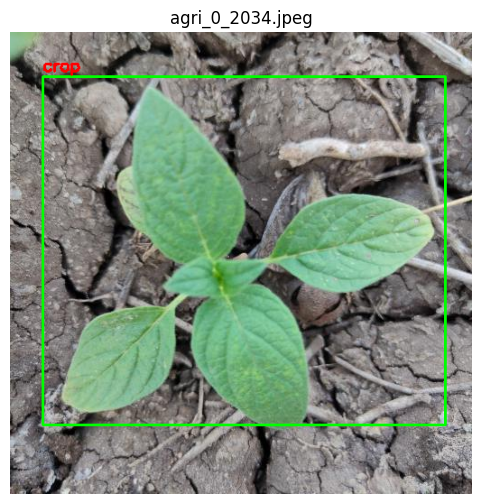

<Figure size 640x480 with 0 Axes>

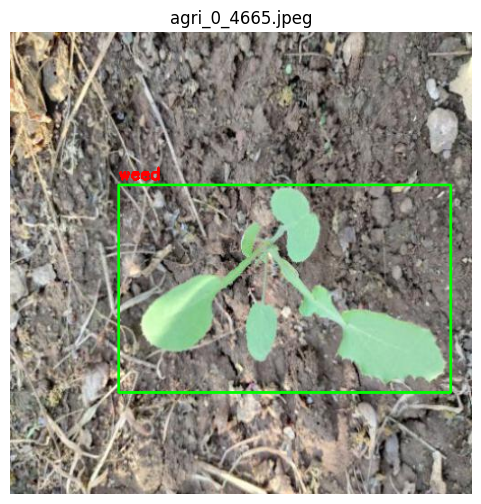

<Figure size 640x480 with 0 Axes>

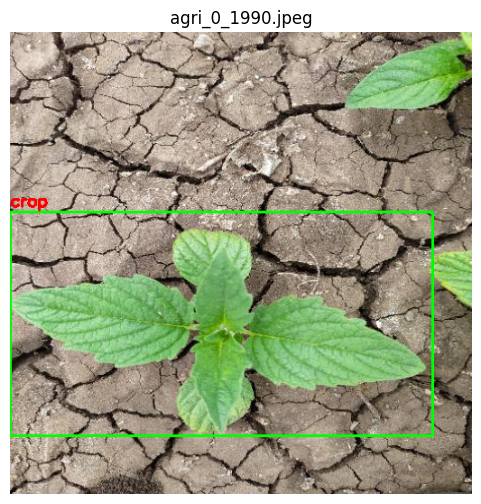


Loading model: yolov8m
Ultralytics 8.3.234 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (NVIDIA A100-SXM4-80GB, 81222MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cropweed_data_cfg/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=yolov8m_exp, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, pat

In [ ]:
!pip install -q ultralytics kagglehub opencv-python pyyaml matplotlib seaborn pandas

import os
import sys
import random
from pathlib import Path
import shutil
import yaml
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
import pandas as pd
from collections import Counter
from glob import glob
import time

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

# -----------------------------------------------------------
# 1. Download Kaggle dataset (read-only location)
# -----------------------------------------------------------
import kagglehub

path = kagglehub.dataset_download(
    "ravirajsinh45/crop-and-weed-detection-data-with-bounding-boxes"
)
print("Dataset downloaded to:", path)

dataset_root = Path(path)
raw_data = dataset_root / "agri_data" / "data"

print("\nSample files:")
for f in list(raw_data.glob("*"))[:10]:
    print(" ", f.name)

# -----------------------------------------------------------
# 2. Copy dataset into a writable directory
# -----------------------------------------------------------
work_dir = Path("/content/cropweed_raw")
work_dir.mkdir(exist_ok=True)

for f in raw_data.glob("*"):
    shutil.copy(f, work_dir / f.name)

print("\nCopied dataset into:", work_dir)

# -----------------------------------------------------------
# 3. Create YOLO-style structure
# -----------------------------------------------------------
yolo_root = Path("/content/cropweed_yolo")

(train_img := yolo_root / "images" / "train").mkdir(parents=True, exist_ok=True)
(train_lbl := yolo_root / "labels" / "train").mkdir(parents=True, exist_ok=True)

# Move JPGs + labels
for f in work_dir.glob("*"):
    if f.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        shutil.move(str(f), str(train_img / f.name))
    elif f.suffix.lower() == ".txt":
        shutil.move(str(f), str(train_lbl / f.name))

print("\nOrganized YOLO dataset at:", yolo_root)

train_images_dir = train_img
train_labels_dir = train_lbl

# -----------------------------------------------------------
# 3b. Train/Val split
# -----------------------------------------------------------
base = str(yolo_root)
img_dir = f"{base}/images/train"
lbl_dir = f"{base}/labels/train"

# New folders (val)
os.makedirs(f"{base}/images/val", exist_ok=True)
os.makedirs(f"{base}/labels/val", exist_ok=True)
os.makedirs(f"{base}/images/train", exist_ok=True)
os.makedirs(f"{base}/labels/train", exist_ok=True)

images = glob(f"{base}/images/train/*")
random.shuffle(images)

split_idx = int(0.9 * len(images))
train_imgs_list = images[:split_idx]
val_imgs_list   = images[split_idx:]

def move_pairs(img_list, target_img_folder, target_lbl_folder):
    for img in img_list:
        name = os.path.basename(img).rsplit('.',1)[0]
        lbl = f"{base}/labels/train/{name}.txt"
        if os.path.exists(lbl):
            shutil.move(img, os.path.join(target_img_folder, os.path.basename(img)))
            shutil.move(lbl, os.path.join(target_lbl_folder, os.path.basename(lbl)))

move_pairs(val_imgs_list, f"{base}/images/val", f"{base}/labels/val")
move_pairs(train_imgs_list, f"{base}/images/train", f"{base}/labels/train")

val_images_dir  = yolo_root / "images" / "val"
val_labels_dir  = yolo_root / "labels" / "val"

# -----------------------------------------------------------
# 4. Try to find existing config or detect class names
# -----------------------------------------------------------
candidate_yaml = list(dataset_root.rglob("data.yaml"))
print("\nFound existing data.yaml files:", candidate_yaml)

if candidate_yaml:
    with open(candidate_yaml[0], "r") as f:
        existing_cfg = yaml.safe_load(f)
        print("\nExisting config:", existing_cfg)

# Dataset classes
class_names = ["crop", "weed"]
nc = len(class_names)
names_dict = {i: n for i, n in enumerate(class_names)}

print("\nNumber of classes:", nc)
print("Class names:", names_dict)

# -----------------------------------------------------------
# 5. Create data.yaml
# -----------------------------------------------------------
yolo_data_root = Path("/content/cropweed_data_cfg")
yolo_data_root.mkdir(parents=True, exist_ok=True)

data_yaml_path = yolo_data_root / "data.yaml"

data_cfg = {
    "path": "/content/cropweed_yolo",
    "train": "images/train",
    "val": "images/val",
    "test": "images/val",
    "nc": nc,
    "names": {i: n for i, n in enumerate(class_names)}
}

with open(data_yaml_path, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)

print("\nWrote data.yaml:")
print(data_yaml_path.read_text())

# -----------------------------------------------------------
# 6. Dataset summary (dataset + num classes, counts)
# -----------------------------------------------------------
train_imgs_glob = glob(str(train_images_dir / "*"))
val_imgs_glob   = glob(str(val_images_dir / "*"))

print("\n=== Dataset Summary ===")
print("Dataset: Kaggle crop-and-weed-detection-data-with-bounding-boxes")
print(f"Number of classes: {len(class_names)} -> {class_names}")
print(f"Train images: {len(train_imgs_glob)}")
print(f"Val images:   {len(val_imgs_glob)}")

# Class counts in train labels
label_files = glob(str(train_labels_dir / "*.txt"))
class_counter = Counter()
for lf in label_files:
    with open(lf, "r") as f:
        for line in f:
            if line.strip():
                cls_id = int(line.strip().split()[0])
                class_counter[cls_id] += 1

decoded_counts = {names_dict[c]: n for c, n in class_counter.items()}
print("Label counts in train set:", decoded_counts)

# -----------------------------------------------------------
# 7. Check image-label consistency
# -----------------------------------------------------------
def check_split(img_dir, lbl_dir):
    img_dir, lbl_dir = Path(img_dir), Path(lbl_dir)
    print(f"\nChecking {img_dir} vs {lbl_dir}")
    img_stems = {p.stem for p in img_dir.glob("*") if p.is_file()}
    lbl_stems = {p.stem for p in lbl_dir.glob("*.txt")}
    missing_lbl = sorted(img_stems - lbl_stems)
    missing_img = sorted(lbl_stems - img_stems)
    print("Total images:", len(img_stems), "labels:", len(lbl_stems))
    if missing_lbl:
        print("Images missing labels:", missing_lbl[:5])
    if missing_img:
        print("Labels missing images:", missing_img[:5])

check_split(train_images_dir, train_labels_dir)
check_split(val_images_dir, val_labels_dir)

# -----------------------------------------------------------
# 8. Visualize sample images + GT boxes (for poster)
# -----------------------------------------------------------
sample_imgs = list(train_images_dir.glob("*"))
random.shuffle(sample_imgs)
sample_imgs = sample_imgs[:3]

def show_image_with_boxes(img_path, lbl_dir, names_dict):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    lbl_path = lbl_dir / (img_path.stem + ".txt")
    if lbl_path.exists():
        for line in open(lbl_path):
            cls, xc, yc, bw, bh = map(float, line.split())
            cls = int(cls)
            xc, yc, bw, bh = xc*w, yc*h, bw*w, bh*h
            x1, y1 = int(xc - bw/2), int(yc - bh/2)
            x2, y2 = int(xc + bw/2), int(yc + bh/2)
            cv2.rectangle(img, (x1,y1), (x2,y2), (0,255,0), 2)
            cv2.putText(img, names_dict[cls], (x1, y1-6),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,0,0), 2)

    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis("off")
    plt.title(img_path.name)
    plt.show()

# Show & save a few GT samples
for i, p in enumerate(sample_imgs):
    show_image_with_boxes(p, train_labels_dir, names_dict)
    plt.savefig(f"sample_gt_{i}.png", bbox_inches="tight")

# -----------------------------------------------------------
# 9. Train YOLO
# -----------------------------------------------------------
device = 0 if torch.cuda.is_available() else "cpu"
model_name = "yolov8m"

print("\nLoading model:", model_name)
model = YOLO(f"{model_name}.pt")

EPOCHS = 40
BATCH_SIZE = 8
IMG_SIZE = 640
PATIENCE = 10

results = model.train(
    data=str(data_yaml_path),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=device,
    patience=PATIENCE,
    project="runs_cropweed",
    name="yolov8m_exp",
    exist_ok=True,
)

# -----------------------------------------------------------
# 10. Evaluate model + key metrics table
# -----------------------------------------------------------
metrics = model.val(
    data=str(data_yaml_path),
    imgsz=IMG_SIZE,
    device=device,
)

print("\nValidation metrics:")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")

metrics_dict = {
    "Metric": ["mAP50", "mAP50-95", "Precision", "Recall"],
    "Value": [
        round(metrics.box.map50, 4),
        round(metrics.box.map, 4),
        round(metrics.box.mp, 4),
        round(metrics.box.mr, 4),
    ]
}
metrics_df = pd.DataFrame(metrics_dict)
print("\n=== Key Metrics Table ===")
print(metrics_df.to_string(index=False))


['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


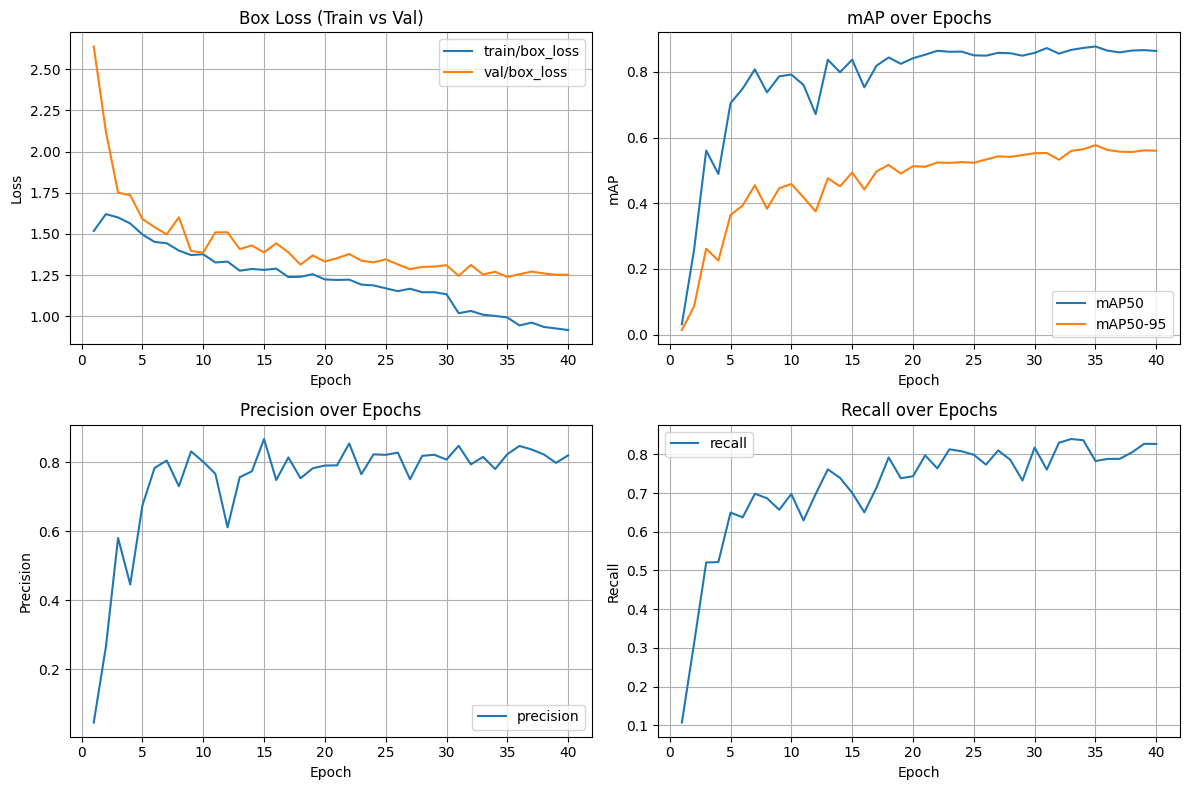


Inference on: /content/cropweed_yolo/images/train

WARNING ⚠️ 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1170 /content/cropweed_yolo/images/train/agri_0_1009.jpeg: 640x640 1 weed, 10.1ms
image 2/1170 /content/cropweed_yolo/images/train/agri_0_1017.jpeg: 640x640 1 weed, 10.1ms
image 3/1170 /content/cropweed_yolo/images/train/agri_0_1018.jpeg: 640x640 1 weed, 10.4ms
image 4/1170 /content/cropweed_yolo/images/train/agri_0_1024.jpeg: 640x640 1 weed, 9.1ms
image 5/1170 /content/cropweed_yolo/images/tra

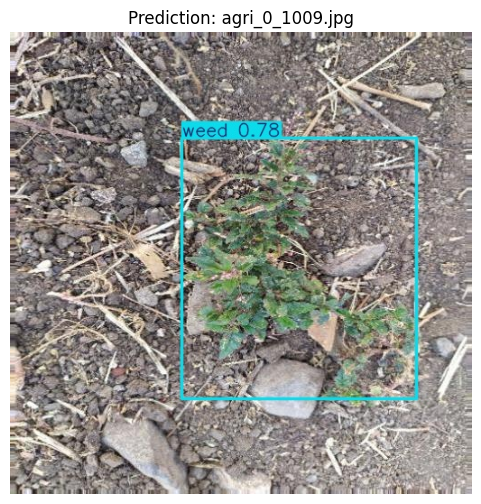

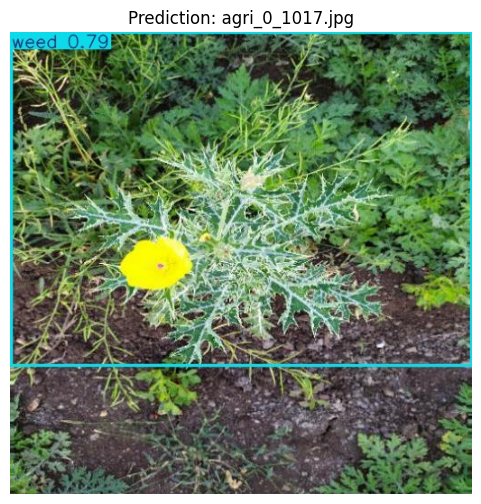

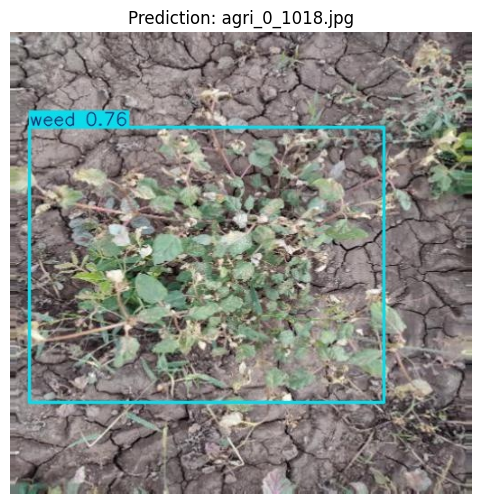


Demo image: /content/cropweed_yolo/images/train/agri_0_718.jpeg


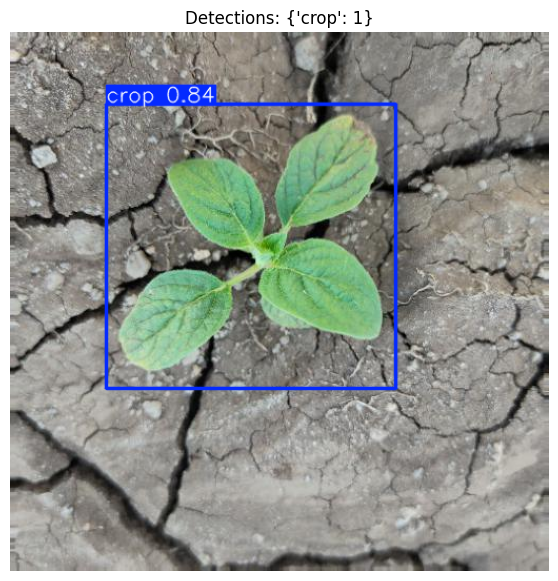

Counts: {'crop': 1}

Model weights: best.pt, size = 49.62 MB
No images found to benchmark FPS.


In [ ]:
# -----------------------------------------------------------
# 11. Training curves (loss, mAP, precision, recall)
# -----------------------------------------------------------
results_dir = Path("runs_cropweed") / "yolov8m_exp"
csv_path = results_dir / "results.csv"

if csv_path.exists():
    df = pd.read_csv(csv_path)
    print(df.columns.tolist())  # sanity check

    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    # 1) Train vs Val Box Loss
    axs[0,0].plot(df["epoch"], df["train/box_loss"], label="train/box_loss")
    axs[0,0].plot(df["epoch"], df["val/box_loss"],   label="val/box_loss")
    axs[0,0].set_title("Box Loss (Train vs Val)")
    axs[0,0].set_xlabel("Epoch")
    axs[0,0].set_ylabel("Loss")
    axs[0,0].legend()
    axs[0,0].grid(True)

    # 2) mAP curves
    axs[0,1].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
    axs[0,1].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
    axs[0,1].set_title("mAP over Epochs")
    axs[0,1].set_xlabel("Epoch")
    axs[0,1].set_ylabel("mAP")
    axs[0,1].legend()
    axs[0,1].grid(True)

    # 3) Precision
    axs[1,0].plot(df["epoch"], df["metrics/precision(B)"], label="precision")
    axs[1,0].set_title("Precision over Epochs")
    axs[1,0].set_xlabel("Epoch")
    axs[1,0].set_ylabel("Precision")
    axs[1,0].legend()
    axs[1,0].grid(True)

    # 4) Recall
    axs[1,1].plot(df["epoch"], df["metrics/recall(B)"], label="recall")
    axs[1,1].set_title("Recall over Epochs")
    axs[1,1].set_xlabel("Epoch")
    axs[1,1].set_ylabel("Recall")
    axs[1,1].legend()
    axs[1,1].grid(True)

    plt.tight_layout()
    plt.savefig("training_curves_labeled.png", bbox_inches="tight")
    plt.show()


# -----------------------------------------------------------
# 12. Run inference + sample predictions (with boxes)
# -----------------------------------------------------------
best_weights = results_dir / "weights" / "best.pt"
best_model = YOLO(str(best_weights)) if best_weights.exists() else model

infer_source = train_images_dir
print("\nInference on:", infer_source)

pred_out = "runs_cropweed/predictions"
best_model.predict(
    source=str(infer_source),
    imgsz=IMG_SIZE,
    conf=0.5,
    device=device,
    save=True,
    project="runs_cropweed",
    name="predictions",
    exist_ok=True,
)

pred_dir = Path(pred_out)
for i, p in enumerate(sorted(pred_dir.glob("*.jpg"))[:3]):
    img = cv2.imread(str(p))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Prediction: {p.name}")
    plt.savefig(f"sample_pred_{i}.png", bbox_inches="tight")
    plt.show()

# -----------------------------------------------------------
# 13. Object counting function (per image)
# -----------------------------------------------------------
def detect_and_count(image_path, model, names_dict, conf=0.5):
    results = model.predict(source=str(image_path), conf=conf, device=device, verbose=False)
    r = results[0]
    class_ids = r.boxes.cls.cpu().numpy().astype(int)
    counts = Counter(class_ids)
    decoded = {names_dict[c]: n for c,n in counts.items()}
    return r, decoded

demo_img = next(iter(infer_source.glob("*")), None)
print("\nDemo image:", demo_img)

if demo_img:
    r, decoded = detect_and_count(demo_img, best_model, names_dict)
    im = r.plot()
    im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(7,7))
    plt.imshow(im)
    plt.axis("off")
    plt.title(f"Detections: {decoded}")
    plt.show()
    print("Counts:", decoded)

# -----------------------------------------------------------
# 14. Optional: Model size + inference FPS
# -----------------------------------------------------------
import os

weights_path = best_weights if best_weights.exists() else Path(f"{model_name}.pt")
size_mb = os.path.getsize(weights_path) / (1024 * 1024)
print(f"\nModel weights: {weights_path.name}, size = {size_mb:.2f} MB")

test_imgs = list(infer_source.glob("*.jpg"))[:50]  # subset
if len(test_imgs) > 0:
    start = time.time()
    _ = best_model.predict(
        source=[str(p) for p in test_imgs],
        imgsz=IMG_SIZE,
        conf=0.5,
        device=device,
        verbose=False,
    )
    elapsed = time.time() - start
    avg_time = elapsed / len(test_imgs)
    fps = 1.0 / avg_time
    print(f"Avg inference time: {avg_time*1000:.2f} ms/image")
    print(f"Approx FPS: {fps:.2f}")
else:
    print("No images found to benchmark FPS.")